# SHAP Values

### Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
plt.style.use('default')

In [3]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error as MSE
from sklearn.metrics import mean_absolute_error as MAE
from sklearn.metrics import r2_score as R2

In [4]:
# $ pip install shap
import shap 

### Functions

In [5]:
def print_feature_importances_random_forest(random_forest_model):
    
    '''
    Prints the feature importances of a Random Forest model in an ordered way.
    random_forest_model -> The sklearn.ensemble.RandomForestRegressor or RandomForestClassifier trained model
    '''
    
    # Fetch the feature importances and feature names
    importances = random_forest_model.feature_importances_
    features = random_forest_model.feature_names_in_
    
    # Organize them in a dictionary
    feature_importances = {fea: imp for imp, fea in zip(importances, features)}
    
    # Sorts the dictionary
    feature_importances = {k: v for k, v in sorted(feature_importances.items(), key=lambda item: item[1], reverse = True)}
    
    # Prints the feature importances
    for k, v in feature_importances.items():
        print(f"{k} -> {v:.4f}")

In [6]:
def print_feature_importances_shap_values(shap_values, features):
    
    '''
    Prints the feature importances based on SHAP values in an ordered way
    shap_values -> The SHAP values calculated from a shap.Explainer object
    features -> The name of the features, on the order presented to the explainer
    '''

    # Calculates the feature importance (mean absolute SHAP value) for each feature
    importances = np.abs(shap_values.values).mean(axis = 0)

    # Each feature's share of the total. The shares add up to 1, like the
    # random forest's own importances, so the two rankings can be compared directly
    shares = importances / importances.sum()

    # Prints the features from most to least important
    for i in np.argsort(importances)[::-1]:
        print(f"{features[i]} -> {importances[i]:.4f} (share = {shares[i]:.4f})")

In [7]:
def evaluate_regression(y, y_pred):
    
    '''
    Prints the most common evaluation metrics for regression
    '''
    
    mae = MAE(y, y_pred)
    mse = MSE(y, y_pred)
    rmse = mse ** (1/2)
    r2 = R2(y, y_pred)
    
    print('Regression result')
    print(f"MAE: {mae:.2f}")
    print(f"MSE: {mse:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R2: {r2:.2f}")

## Regression

### Import a regression dataset

In [8]:
from sklearn.datasets import fetch_california_housing

In [9]:
dataset = fetch_california_housing(as_frame = True)

In [10]:
print(dataset['DESCR'])

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

In [11]:
# Gets the independent variables
X = dataset['data']  
X.head(5)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [12]:
# Checks the shape of the data
X.shape

(20640, 8)

In [13]:
# Gets the dependent variable (the target)
y = dataset['target']
y.head(5)

0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64

### Create a simple regression

In [14]:
# random_state fixes the split, so every number below is the same on each run
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [15]:
# Prepares a default instance of the random forest regressor
# random_state makes it repeatable; n_jobs = -1 uses every CPU core, which also speeds up SHAP below
model = RandomForestRegressor(random_state = 42, n_jobs = -1)

In [16]:
# Fits the model on the data
model.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [17]:
# Evaluates the model
y_pred = model.predict(X_test)
evaluate_regression(y_test, y_pred)

Regression result
MAE: 0.33
MSE: 0.26
RMSE: 0.51
R2: 0.80


In [18]:
# Prints the feature importances
print_feature_importances_random_forest(model)

MedInc -> 0.5250
AveOccup -> 0.1384
Latitude -> 0.0890
Longitude -> 0.0885
HouseAge -> 0.0546
AveRooms -> 0.0442
Population -> 0.0307
AveBedrms -> 0.0297


### SHAP values

In [19]:
# Fits the explainer. The background data (100 training rows) sets the baseline:
# a SHAP value is how far a feature moves the prediction away from the average over these rows
background = shap.sample(X_train, 100, random_state = 0)
explainer = shap.Explainer(model.predict, background)

In [20]:
# Calculates the SHAP values on a sample of the test set.
# 500 rows takes about a minute and gives the same picture as the whole
# test set (~4,100 rows), which takes about 8 times as long.
# Set N_EXPLAIN = None to explain the whole test set.
# For tree models, shap.TreeExplainer(model)(X_test) is exact and takes seconds.
N_EXPLAIN = 500
X_explain = X_test if N_EXPLAIN is None else X_test.sample(N_EXPLAIN, random_state=0)
shap_values = explainer(X_explain)

In [21]:
shap_values

.values =
array([[-0.31103516, -0.00706093,  0.12407335, ..., -0.30343732,
         0.33921758,  0.01943022],
       [-0.24836718,  0.01414357, -0.04701559, ..., -0.10256861,
         0.31947507,  0.17285247],
       [-0.13371466,  0.01835728, -0.02313687, ..., -0.19814983,
        -0.12757356,  0.97963884],
       ...,
       [ 0.31599429,  0.13754635,  0.00315597, ..., -0.04554614,
         0.31949172, -0.14531611],
       [ 2.58366142, -0.07613823,  0.21286269, ..., -0.1407486 ,
         0.26885967, -0.13713948],
       [ 0.85061201, -0.03458276,  0.06990955, ...,  0.01404913,
        -0.50272282,  0.57464065]], shape=(500, 8))

.base_values =
array([1.98710552, 1.98710552, 1.98710552, 1.98710552, 1.98710552,
       1.98710552, 1.98710552, 1.98710552, 1.98710552, 1.98710552,
       1.98710552, 1.98710552, 1.98710552, 1.98710552, 1.98710552,
       1.98710552, 1.98710552, 1.98710552, 1.98710552, 1.98710552,
       1.98710552, 1.98710552, 1.98710552, 1.98710552, 1.98710552,
       1.9

### SHAP global evaluation

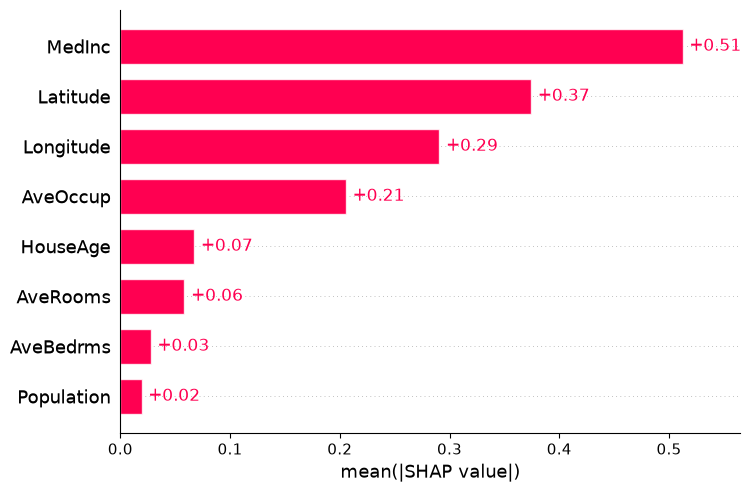

In [22]:
# Plots this view
shap.plots.bar(shap_values)

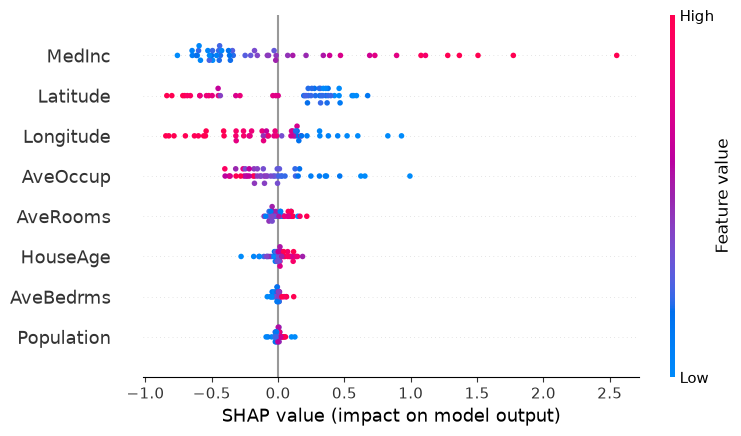

In [23]:
# Plots the beeswarm
shap.plots.beeswarm(shap_values.sample(50))

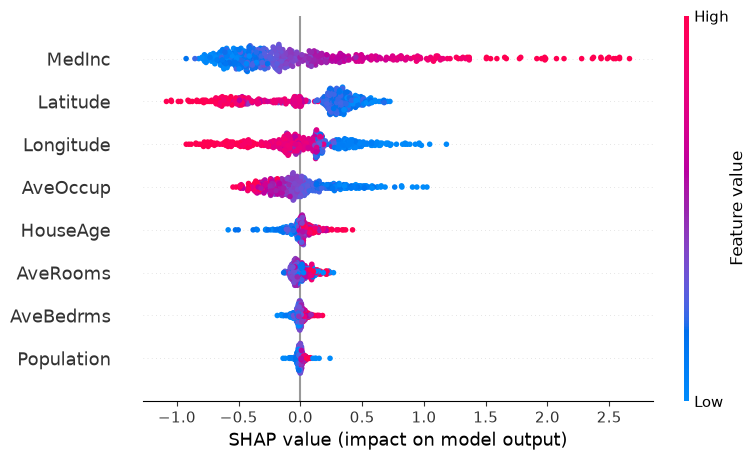

In [24]:
shap.summary_plot(shap_values)

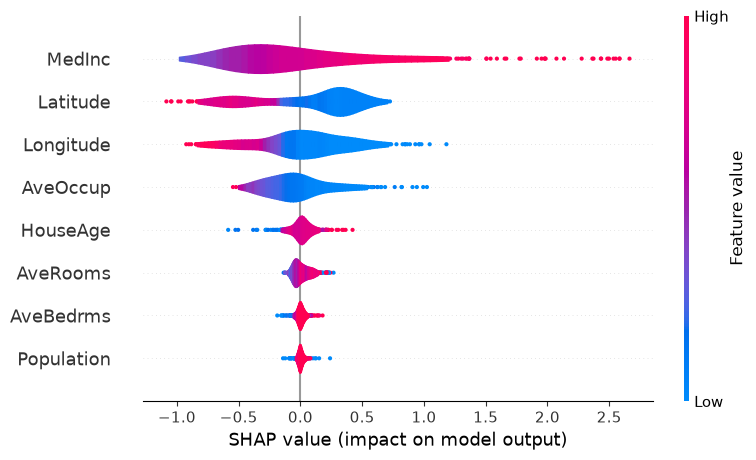

In [25]:
# Violin plot
shap.summary_plot(shap_values, plot_type='violin')

In [26]:
# Prints the SHAP feature importances
print_feature_importances_shap_values(shap_values, X_test.columns)

MedInc -> 0.5125 (share = 0.3293)
Latitude -> 0.3744 (share = 0.2406)
Longitude -> 0.2908 (share = 0.1868)
AveOccup -> 0.2057 (share = 0.1321)
HouseAge -> 0.0674 (share = 0.0433)
AveRooms -> 0.0585 (share = 0.0376)
AveBedrms -> 0.0278 (share = 0.0178)
Population -> 0.0194 (share = 0.0124)


### SHAP local evaluation
For a single example

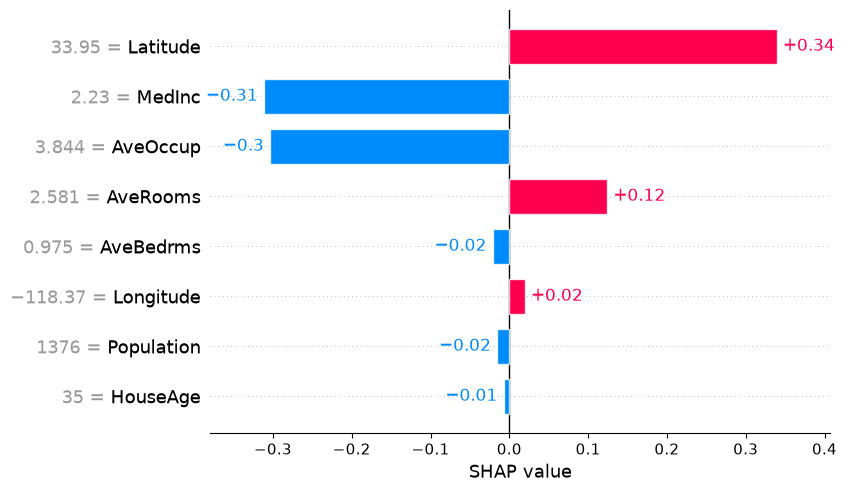

In [27]:
shap.plots.bar(shap_values[0])

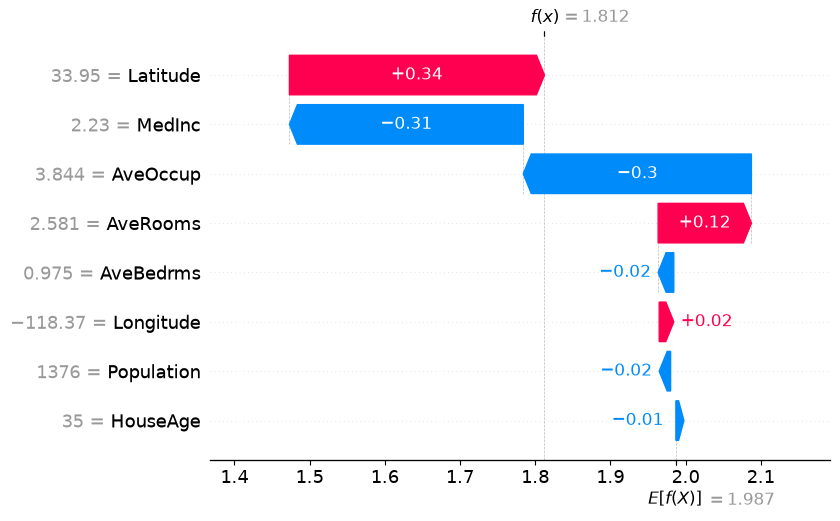

In [28]:
shap.plots.waterfall(shap_values[0], max_display=10)

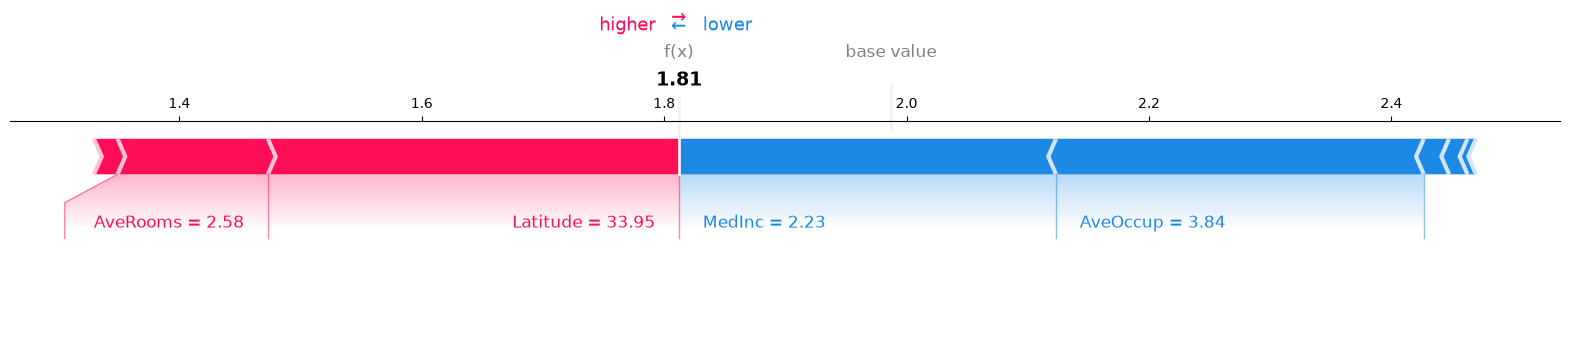

In [29]:
# matplotlib = True draws a static image, which also shows in VS Code, on GitHub and in exported files.
# For the interactive version in Jupyter, run: shap.initjs(); shap.plots.force(shap_values[0])
row = shap_values[0]
# Rounds the feature values so the labels stay readable
shap.plots.force(row.base_values, row.values, row.data.round(2), feature_names = row.feature_names, matplotlib = True)